# EBM multi-escala — Denoising Score Matching en MNIST (versión mejorada, estilo NCSNv2)

Entrena una red de score condicionada en el nivel de ruido $\sigma$ con **denoising score matching** y genera con
**Langevin recocido (annealed)**. Esta versión aplica las técnicas de Song & Ermon (2020), *Improved Techniques for
Training Score-Based Generative Models* (NCSNv2), que resuelven exactamente los síntomas que veías: dígitos rotos,
formas que "se deciden mal" y puntos sueltos.

## Qué fallaba y qué se ha cambiado

| En tu versión | Por qué daba problemas | Cambio | Fuente |
|---|---|---|---|
| $\sigma_1 = 1$ | En MNIST la distancia mediana entre dos imágenes es ≈ 10 y la máxima ≈ 16. Con $\sigma_1 = 1$ la cadena **no puede pasar de un dígito a otro**: se queda con la primera forma que encuentra, aunque sea mala | $\sigma_1$ = distancia máxima entre imágenes, **calculada con los datos** (≈ 16) | NCSNv2, Técnica 1 |
| $L = 20$ niveles ($\gamma \approx 1.27$) | Con 784 dimensiones, dos niveles tan separados **casi no se solapan**: la muestra de un nivel llega a zonas donde el score del siguiente no es fiable | razón $\gamma$ calculada para que se solapen al 50 % → $\gamma \approx 1.08$, $L \approx 95$ | NCSNv2, Técnica 2 |
| `step_lr` y pasos por nivel ajustados a mano | Nada garantiza que en cada nivel la cadena llegue al ruido correcto | $T = 5$ pasos por nivel y $\epsilon$ **calculado** con la Ec. (4) del paper | NCSNv2, Técnica 4 |
| Se muestrea con los pesos del último paso | La calidad oscila entre épocas (tu pico en las épocas 35-36) | **EMA** de los pesos (0.999) para muestrear | NCSNv2, Técnica 5 |
| Sin paso final de limpieza | Queda ruido residual → puntos sueltos | Paso final $x + \sigma_L^2\, s_\theta(x, \sigma_L)$ (fórmula de Tweedie) | NCSNv2, Alg. 1 |
| Entrada sin normalizar, $\sigma$ solo como canal de entrada | Con $\sigma$ hasta 16 la entrada llega a valores de ±50 en una red sin normalización; la información de $\sigma$ solo entra en la primera capa | Escalado de entrada, GroupNorm y **embedding de $\sigma$ en cada bloque** del U-Net | práctica estándar (NCSN++, DDPM) |
| `per_sigma_loss` usaba `.mean()` y el entrenamiento `.sum()` | Las dos cifras no eran comparables | Misma fórmula en ambos sitios; la pérdida por nivel se registra durante el entrenamiento | — |

Se mantiene todo lo que ya funcionaba: datos en $[0,1]$, U-Net 28 → 14 → 7, salida dividida por $\sigma$
(NCSNv2, Técnica 3) y la pérdida con ponderación $\sigma^2$.

El notebook tiene **la misma estructura que el de PCD** (configuración, checkpoints, curvas, evolución, 64 muestras,
evaluación con clasificador y guardado), para que puedas comparar los dos métodos lado a lado.

## Idea en fórmulas (para la memoria)

**Pérdida (DSM multi-escala).** Con $\tilde x = x + \sigma z$, $z\sim\mathcal N(0,I)$:

$$\mathcal L(\theta) = \mathbb E_{\sigma}\,\mathbb E_{x,z}\Big[\sigma^2\,\big\|s_\theta(\tilde x,\sigma) + \tfrac{z}{\sigma}\big\|^2\Big]
= \mathbb E\Big[\big\|\sigma\, s_\theta(\tilde x,\sigma) + z\big\|^2\Big]$$

**Muestreo (Langevin recocido, Algoritmo 1 de NCSNv2).** Para $i = 1,\dots,L$ con $\alpha_i = \epsilon\,\sigma_i^2/\sigma_L^2$:

$$x \leftarrow x + \alpha_i\, s_\theta(x,\sigma_i) + \sqrt{2\alpha_i}\, z$$

y al final $x \leftarrow x + \sigma_L^2\, s_\theta(x,\sigma_L)$.

> Cambio respecto a tu versión: antes usabas $x + \tfrac{\alpha}{2}s + \sqrt{\alpha}\,z$ (forma de NCSN v1). Es el mismo
> algoritmo con otro nombre para el paso; aquí se usa la forma de NCSNv2 porque la fórmula para calcular $\epsilon$
> está escrita para ella.

**Diferencia clave con PCD:** aquí **no hay MCMC durante el entrenamiento**; la pérdida es una regresión estable y
baja de forma monótona. El coste se traslada al muestreo ($L \times T$ evaluaciones de la red por muestra).

In [1]:
import os, json, time, math, copy, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## Configuración

In [2]:
QUICK_TEST = False   # True -> pasada corta para comprobar que todo corre

CFG = dict(
    seed          = 42,
    # datos
    batch_size    = 128,
    # niveles de ruido (NCSNv2)
    sigma_1       = "auto",   # "auto" = distancia máxima entre imágenes (Técnica 1); o un número
    sigma_L       = 0.01,
    overlap_C     = 0.5,      # solapamiento entre niveles consecutivos (Técnica 2)
    # muestreo
    T             = 5,        # pasos de Langevin por nivel (Técnica 4)
    eps           = "auto",   # "auto" = calculado con la Ec. (4); o un número
    # red
    channels      = 64,
    # optimización
    lr            = 1e-4,
    grad_clip     = 1.0,
    ema_decay     = 0.999,    # Técnica 5
    epochs        = 60,       # mismas épocas que el PCD
    max_iters_per_epoch = None,
    # monitorización
    vis_every     = 5,
    ckpt_dir      = "checkpoints_dsm",
    pcd_samples_path = "resultados_pcd/muestras_pcd_01.pt",   # para la comparación final (si existe)
)

if QUICK_TEST:
    CFG.update(epochs=2, max_iters_per_epoch=30, vis_every=1, T=1)

os.makedirs(CFG["ckpt_dir"], exist_ok=True)
set_seed(CFG["seed"])
IMG_SHAPE = (1, 28, 28)
D = int(np.prod(IMG_SHAPE))
CFG

{'seed': 42,
 'batch_size': 128,
 'sigma_1': 'auto',
 'sigma_L': 0.01,
 'overlap_C': 0.5,
 'T': 5,
 'eps': 'auto',
 'channels': 64,
 'lr': 0.0001,
 'grad_clip': 1.0,
 'ema_decay': 0.999,
 'epochs': 60,
 'max_iters_per_epoch': None,
 'vis_every': 5,
 'ckpt_dir': 'checkpoints_dsm',
 'pcd_samples_path': 'resultados_pcd/muestras_pcd_01.pt'}

## Datos (en $[0, 1]$, como antes)

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.49MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 125kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.22MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.06MB/s]


torch.Size([128, 1, 28, 28]) 0.0 1.0


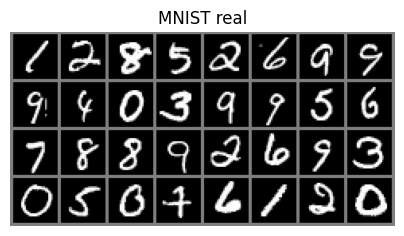

In [3]:
transform = transforms.ToTensor()   # [0, 1]

train_ds = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_ds  = datasets.MNIST("./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True,
                          num_workers=2, drop_last=True, pin_memory=True)
test_loader  = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=2)

def show_grid(x, nrow=8, title=None, size=5):
    grid = torchvision.utils.make_grid(x.detach().cpu().clamp(0, 1), nrow=nrow, padding=2, pad_value=0.5)
    plt.figure(figsize=(size, size * grid.shape[1] / grid.shape[2]))
    plt.imshow(grid.permute(1, 2, 0).numpy(), cmap="gray")
    plt.axis("off")
    if title: plt.title(title)
    plt.show()

x_real, _ = next(iter(train_loader))
print(x_real.shape, x_real.min().item(), x_real.max().item())
show_grid(x_real[:32], title="MNIST real")

## Niveles de ruido y paso de Langevin (calculados, no a mano)

**Técnica 1.** $\sigma_1 \approx$ distancia euclídea máxima entre imágenes de entrenamiento. Se estima con 10 000
imágenes (suficiente: la máxima con todo el conjunto apenas cambia).

**Técnica 2.** Secuencia geométrica con razón $\gamma$ tal que

$$\Phi\big(\sqrt{2D}(\gamma-1)+3\gamma\big) - \Phi\big(\sqrt{2D}(\gamma-1)-3\gamma\big) \approx 0.5$$

**Técnica 4.** Fijado $T$, se busca $\epsilon$ que deje la Ec. (4) del paper lo más cerca posible de 1, es decir,
que al terminar los $T$ pasos de cada nivel la muestra tenga exactamente el ruido de ese nivel.

distancia máxima ≈ 16.88 | mediana ≈ 10.22
gamma = 1.0814 (solapamiento 0.51) | L = 96 niveles
con tu configuración anterior (gamma ≈ 1.274) el solapamiento era 1.05e-12
T = 5 | eps = 1.105e-05 | Ec.(4) = 1.093 (ideal 1)
evaluaciones de la red por muestra: 481  (PCD: 256 pasos al generar desde ruido)


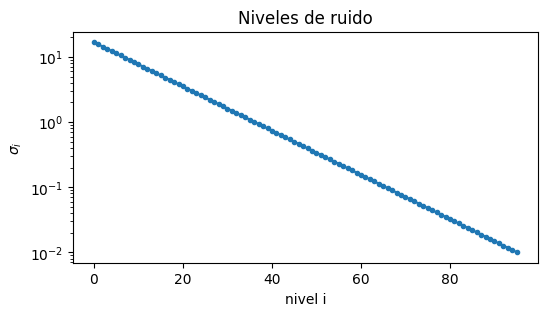

In [4]:
# --- Técnica 1: sigma_1 ---
@torch.no_grad()
def max_pairwise_distance(n=10000, chunk=1000):
    idx = torch.randperm(len(train_ds))[:n]
    X = (train_ds.data[idx].float() / 255.).view(n, -1).to(device)
    dmax, meds = 0.0, []
    for i in range(0, n, chunk):
        d = torch.cdist(X[i:i + chunk], X)
        dmax = max(dmax, d.max().item())
        meds.append(d.flatten()[torch.randint(0, d.numel(), (5000,), device=device)])
    return dmax, torch.cat(meds).median().item()

dmax, dmed = max_pairwise_distance()
print(f"distancia máxima ≈ {dmax:.2f} | mediana ≈ {dmed:.2f}")
sigma_1 = dmax if CFG["sigma_1"] == "auto" else float(CFG["sigma_1"])
sigma_L = CFG["sigma_L"]

# --- Técnica 2: razón gamma y número de niveles ---
def Phi(v):
    return 0.5 * (1 + math.erf(v / math.sqrt(2)))

def overlap(gamma, D):
    a = math.sqrt(2 * D) * (gamma - 1)
    return Phi(a + 3 * gamma) - Phi(a - 3 * gamma)

lo, hi = 1.0 + 1e-9, 2.0
for _ in range(100):                      # bisección: el solapamiento baja al subir gamma
    mid = (lo + hi) / 2
    lo, hi = (mid, hi) if overlap(mid, D) > CFG["overlap_C"] else (lo, mid)
gamma_target = (lo + hi) / 2

L = int(math.ceil(math.log(sigma_1 / sigma_L) / math.log(gamma_target))) + 1
sigmas = torch.tensor(np.geomspace(sigma_1, sigma_L, L), dtype=torch.float32, device=device)
gamma = (sigmas[0] / sigmas[1]).item()
print(f"gamma = {gamma:.4f} (solapamiento {overlap(gamma, D):.2f}) | L = {L} niveles")
print(f"con tu configuración anterior (gamma ≈ 1.274) el solapamiento era {overlap(1.274, D):.2e}")

# --- Técnica 4: epsilon ---
def eq4_ratio(eps, T, gamma, sL):
    a = eps / sL ** 2
    b = 2.0 / (2.0 - a)
    return (1 - a) ** (2 * T) * (gamma ** 2 - b) + b

if CFG["eps"] == "auto":
    grid = np.logspace(-9, math.log10(0.5 * sigma_L ** 2), 20000)
    ratios = np.array([eq4_ratio(e, CFG["T"], gamma, sigma_L) for e in grid])
    eps = float(grid[np.argmin(np.abs(ratios - 1))])
else:
    eps = float(CFG["eps"])
print(f"T = {CFG['T']} | eps = {eps:.3e} | Ec.(4) = {eq4_ratio(eps, CFG['T'], gamma, sigma_L):.3f} (ideal 1)")

NFE = L * CFG["T"] + 1
print(f"evaluaciones de la red por muestra: {NFE}  (PCD: 256 pasos al generar desde ruido)")

plt.figure(figsize=(6, 3))
plt.semilogy(sigmas.cpu().numpy(), ".-")
plt.xlabel("nivel i"); plt.ylabel(r"$\sigma_i$"); plt.title("Niveles de ruido")
plt.show()

## Red de score (U-Net condicionado en $\sigma$)

Misma topología que tenías (28 → 14 → 7 → 14 → 28 con skip connections), con tres mejoras:

1. **Escalado de entrada:** la red recibe $(x-0.5)/\sqrt{\sigma^2 + 0.5^2}$, que tiene magnitud ~1 para cualquier $\sigma$.
2. **Embedding de $\sigma$** (características de Fourier de $\log\sigma$ + MLP) que se suma en **cada bloque**, no solo
   en la entrada.
3. **GroupNorm + bloques residuales**, lo habitual en U-Nets de difusión.

La salida se sigue dividiendo por $\sigma$ (Técnica 3). La última convolución se inicializa a cero, así que al
principio el score es 0.

In [5]:
class FourierEmbedding(nn.Module):
    def __init__(self, dim=64, scale=16.0):
        super().__init__()
        self.register_buffer("W", torch.randn(dim // 2) * scale)

    def forward(self, t):
        proj = 2 * math.pi * t[:, None] * self.W[None, :]
        return torch.cat([proj.sin(), proj.cos()], dim=-1)


class ResBlock(nn.Module):
    def __init__(self, cin, cout, emb_dim, groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups, cin)
        self.conv1 = nn.Conv2d(cin, cout, 3, padding=1)
        self.emb = nn.Linear(emb_dim, cout)
        self.norm2 = nn.GroupNorm(groups, cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
        self.act = nn.SiLU()

    def forward(self, x, emb):
        h = self.conv1(self.act(self.norm1(x)))
        h = h + self.emb(emb)[:, :, None, None]
        h = self.conv2(self.act(self.norm2(h)))
        return h + self.skip(x)


class ScoreUNet(nn.Module):
    def __init__(self, channels=64, emb_dim=128, sigma_data=0.5):
        super().__init__()
        c = channels
        self.sigma_data = sigma_data
        self.embed = nn.Sequential(
            FourierEmbedding(emb_dim), nn.Linear(emb_dim, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))

        self.conv_in = nn.Conv2d(1, c, 3, padding=1)
        self.enc1  = ResBlock(c, c, emb_dim)                              # 28x28
        self.down1 = nn.Conv2d(c, c, 4, stride=2, padding=1)              # -> 14x14
        self.enc2  = ResBlock(c, 2 * c, emb_dim)                          # 14x14
        self.down2 = nn.Conv2d(2 * c, 2 * c, 4, stride=2, padding=1)      # -> 7x7
        self.mid1  = ResBlock(2 * c, 2 * c, emb_dim)                      # 7x7
        self.mid2  = ResBlock(2 * c, 2 * c, emb_dim)
        self.up2   = nn.ConvTranspose2d(2 * c, 2 * c, 4, stride=2, padding=1)  # -> 14x14
        self.dec2  = ResBlock(4 * c, c, emb_dim)                          # concat con enc2
        self.up1   = nn.ConvTranspose2d(c, c, 4, stride=2, padding=1)          # -> 28x28
        self.dec1  = ResBlock(2 * c, c, emb_dim)                          # concat con enc1
        self.out = nn.Sequential(nn.GroupNorm(8, c), nn.SiLU(), nn.Conv2d(c, 1, 3, padding=1))
        nn.init.zeros_(self.out[-1].weight); nn.init.zeros_(self.out[-1].bias)

    def forward(self, x, sigma):
        # x: (B,1,28,28) en la escala de los datos ([0,1] + ruido);  sigma: (B,)
        s = sigma.view(-1, 1, 1, 1)
        x_in = (x - 0.5) / torch.sqrt(s ** 2 + self.sigma_data ** 2)
        emb = self.embed(torch.log(sigma) / 4)

        e1 = self.enc1(self.conv_in(x_in), emb)
        e2 = self.enc2(self.down1(e1), emb)
        m = self.mid2(self.mid1(self.down2(e2), emb), emb)
        d2 = self.dec2(torch.cat([self.up2(m), e2], dim=1), emb)
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1), emb)
        return self.out(d1) / s          # score s_theta(x, sigma)  (Técnica 3)


model = ScoreUNet(CFG["channels"]).to(device)
ema = copy.deepcopy(model).eval()
for p in ema.parameters():
    p.requires_grad_(False)
print("parámetros:", sum(p.numel() for p in model.parameters()))

parámetros: 1980929


## Pérdida

In [6]:
def dsm_loss(model, x, sigmas):
    B = x.shape[0]
    idx = torch.randint(0, len(sigmas), (B,), device=x.device)
    sigma = sigmas[idx]
    sigma_ = sigma.view(-1, 1, 1, 1)

    z = torch.randn_like(x)
    score = model(x + sigma_ * z, sigma)

    # sigma^2 * ||score - (-z/sigma)||^2  ==  ||sigma*score + z||^2   (misma pérdida que tenías)
    per_sample = ((sigma_ * score + z) ** 2).sum(dim=(1, 2, 3))
    return per_sample.mean(), per_sample.detach(), idx

## Muestreador: Langevin recocido

Además de las muestras, devuelve un diagnóstico por nivel: el **ruido efectivo** de la muestra,
$\|\sigma_i^2 s_\theta(x,\sigma_i)\| / (\sigma_i\sqrt D)$. Si la cadena está donde debe, vale ≈ 1 en todos los niveles
(es la comprobación empírica de la Técnica 4). Si se aleja mucho de 1, el muestreo no está bien ajustado.

In [7]:
@torch.no_grad()
def annealed_langevin(net, n=16, T=None, eps_=None, x_init=None, seed=None,
                      denoise=True, snap_levels=None, batch_size=250):
    T = CFG["T"] if T is None else T
    eps_ = eps if eps_ is None else eps_
    gen = torch.Generator(device=device).manual_seed(seed) if seed is not None else None
    randn = lambda shape: torch.randn(shape, generator=gen, device=device)
    rand = lambda shape: torch.rand(shape, generator=gen, device=device)
    net.eval()

    outs, snaps_all, noise_all = [], [], []
    for start in range(0, n, batch_size):
        b = min(batch_size, n - start)
        if x_init is not None:
            x = x_init[start:start + b].to(device).clone()
        else:
            x = rand((b, *IMG_SHAPE)) + sigmas[0] * randn((b, *IMG_SHAPE))   # ~ p_sigma1
        snaps, eff_noise = {}, []
        for i, s in enumerate(sigmas):
            alpha = eps_ * (s / sigmas[-1]) ** 2
            s_b = s.expand(b)
            for _ in range(T):
                score = net(x, s_b)
                x = x + alpha * score + torch.sqrt(2 * alpha) * randn(x.shape)
            eff_noise.append(((s ** 2 * score).flatten(1).norm(dim=1) / (s * math.sqrt(D))).mean().item())
            if snap_levels is not None and i in snap_levels:
                snaps[i] = x.clamp(0, 1).cpu()
        if denoise:
            x = x + sigmas[-1] ** 2 * net(x, sigmas[-1].expand(b))
        outs.append(x.clamp(0, 1).cpu())
        snaps_all.append(snaps); noise_all.append(eff_noise)

    x = torch.cat(outs)
    if snap_levels is not None:
        snaps = {k: torch.cat([s[k] for s in snaps_all]) for k in snap_levels}
        return x, snaps, np.mean(noise_all, axis=0)
    return x

## Entrenamiento

Se registra la pérdida por iteración y, por época, la pérdida media **por nivel de ruido** (sin coste extra: sale
del propio lote). Cada `vis_every` épocas se generan 16 muestras con la **EMA**, siempre desde **el mismo ruido y la
misma semilla**, así que la comparación entre épocas refleja solo el cambio del modelo.

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=CFG["lr"])

hist_it = {"loss": []}
hist_ep = {"epoch": [], "loss": [], "loss_per_sigma": [], "time_s": []}

@torch.no_grad()
def ema_update():
    for pe, pm in zip(ema.parameters(), model.parameters()):
        pe.lerp_(pm, 1 - CFG["ema_decay"])
    for be, bm in zip(ema.buffers(), model.buffers()):
        be.copy_(bm)

def save_checkpoint(epoch, name=None):
    state = dict(epoch=epoch, cfg=CFG, sigmas=sigmas.cpu(), eps=eps,
                 model=model.state_dict(), ema=ema.state_dict(), optimizer=optimizer.state_dict(),
                 hist_it=hist_it, hist_ep=hist_ep)
    torch.save(state, os.path.join(CFG["ckpt_dir"], name or f"epoch_{epoch:03d}.pt"))

def load_checkpoint(epoch=None, name=None):
    path = os.path.join(CFG["ckpt_dir"], name or f"epoch_{epoch:03d}.pt")
    state = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(state["model"]); ema.load_state_dict(state["ema"])
    optimizer.load_state_dict(state["optimizer"])
    print("cargado", path)
    return state["epoch"]

vis_init = None   # se fija en la primera visualización

def train_one_epoch():
    model.train()
    sum_l = torch.zeros(L, device=device); cnt_l = torch.zeros(L, device=device)
    total, n_it = 0.0, 0
    for it, (x, _) in enumerate(train_loader):
        if CFG["max_iters_per_epoch"] and it >= CFG["max_iters_per_epoch"]:
            break
        x = x.to(device, non_blocking=True)
        loss, per_sample, idx = dsm_loss(model, x, sigmas)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        optimizer.step()
        ema_update()

        if not torch.isfinite(loss):
            raise RuntimeError("Pérdida no finita. Recarga un checkpoint anterior.")
        sum_l.index_add_(0, idx, per_sample); cnt_l.index_add_(0, idx, torch.ones_like(per_sample))
        hist_it["loss"].append(loss.item()); total += loss.item(); n_it += 1
    return total / n_it, (sum_l / cnt_l.clamp(min=1)).cpu().tolist()

época   1/60 |   39.0s | loss  145.1300 | loss(σ grande)  74.6257 | loss(σ pequeño) 234.7292
época   2/60 |   39.5s | loss   55.3768 | loss(σ grande)   6.3363 | loss(σ pequeño) 114.9303
época   3/60 |   40.8s | loss   50.4530 | loss(σ grande)   5.2979 | loss(σ pequeño) 105.5969
época   4/60 |   40.3s | loss   48.3117 | loss(σ grande)   4.8592 | loss(σ pequeño) 101.7926
época   5/60 |   40.5s | loss   46.3100 | loss(σ grande)   4.5905 | loss(σ pequeño)  98.9284


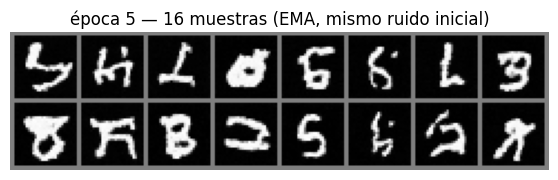

época   6/60 |   40.4s | loss   45.7230 | loss(σ grande)   4.4530 | loss(σ pequeño)  97.4158
época   7/60 |   40.3s | loss   44.6520 | loss(σ grande)   4.3040 | loss(σ pequeño)  96.2434
época   8/60 |   40.3s | loss   44.3724 | loss(σ grande)   4.2377 | loss(σ pequeño)  95.3545
época   9/60 |   40.3s | loss   43.8885 | loss(σ grande)   4.1594 | loss(σ pequeño)  94.2097
época  10/60 |   40.4s | loss   43.1729 | loss(σ grande)   4.1052 | loss(σ pequeño)  93.7418


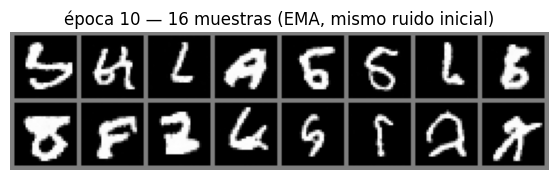

época  11/60 |   40.5s | loss   43.4042 | loss(σ grande)   4.0624 | loss(σ pequeño)  93.1969
época  12/60 |   40.5s | loss   43.1120 | loss(σ grande)   4.0442 | loss(σ pequeño)  92.8325
época  13/60 |   40.4s | loss   42.6428 | loss(σ grande)   4.0008 | loss(σ pequeño)  92.4238
época  14/60 |   40.3s | loss   42.6751 | loss(σ grande)   3.9721 | loss(σ pequeño)  92.0839
época  15/60 |   40.4s | loss   42.4447 | loss(σ grande)   3.9466 | loss(σ pequeño)  91.4639


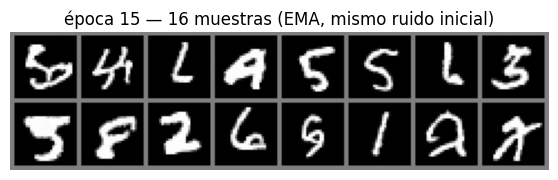

época  16/60 |   40.4s | loss   42.0671 | loss(σ grande)   3.9254 | loss(σ pequeño)  91.2040
época  17/60 |   40.4s | loss   41.7828 | loss(σ grande)   3.9126 | loss(σ pequeño)  90.5930
época  18/60 |   40.4s | loss   41.7596 | loss(σ grande)   3.8913 | loss(σ pequeño)  90.7611
época  19/60 |   40.3s | loss   41.4786 | loss(σ grande)   3.8622 | loss(σ pequeño)  90.1196
época  20/60 |   40.3s | loss   41.5791 | loss(σ grande)   3.8180 | loss(σ pequeño)  90.2089


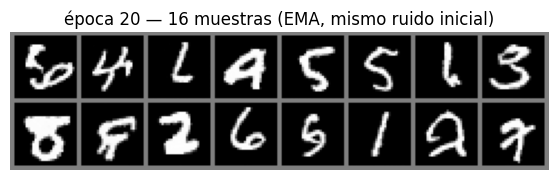

época  21/60 |   40.3s | loss   41.0641 | loss(σ grande)   3.8666 | loss(σ pequeño)  89.6240
época  22/60 |   40.3s | loss   41.1858 | loss(σ grande)   3.8469 | loss(σ pequeño)  89.5788
época  23/60 |   40.3s | loss   41.0547 | loss(σ grande)   3.8046 | loss(σ pequeño)  89.4150
época  24/60 |   40.4s | loss   40.9906 | loss(σ grande)   3.8050 | loss(σ pequeño)  89.2675
época  25/60 |   40.5s | loss   41.0819 | loss(σ grande)   3.7914 | loss(σ pequeño)  89.0306


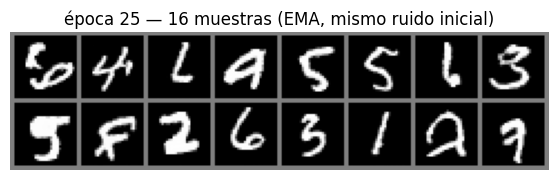

época  26/60 |   40.3s | loss   40.9623 | loss(σ grande)   3.7913 | loss(σ pequeño)  88.7683
época  27/60 |   40.3s | loss   40.8989 | loss(σ grande)   3.7823 | loss(σ pequeño)  88.7162
época  28/60 |   40.4s | loss   40.7780 | loss(σ grande)   3.7636 | loss(σ pequeño)  88.6093
época  29/60 |   40.5s | loss   40.6792 | loss(σ grande)   3.7710 | loss(σ pequeño)  88.1882
época  30/60 |   40.5s | loss   40.7629 | loss(σ grande)   3.7440 | loss(σ pequeño)  88.3383


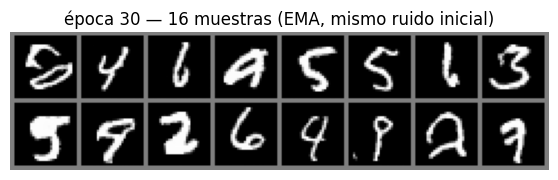

época  31/60 |   40.5s | loss   40.6514 | loss(σ grande)   3.7586 | loss(σ pequeño)  88.2541
época  32/60 |   40.4s | loss   40.6113 | loss(σ grande)   3.7344 | loss(σ pequeño)  87.6699
época  33/60 |   40.4s | loss   40.3340 | loss(σ grande)   3.7281 | loss(σ pequeño)  87.8675
época  34/60 |   40.4s | loss   40.2704 | loss(σ grande)   3.7023 | loss(σ pequeño)  87.8993
época  35/60 |   40.3s | loss   40.2628 | loss(σ grande)   3.7225 | loss(σ pequeño)  87.5799


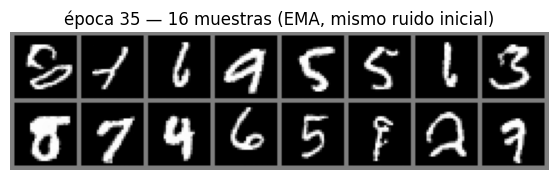

época  36/60 |   40.9s | loss   40.0857 | loss(σ grande)   3.7450 | loss(σ pequeño)  87.3961
época  37/60 |   40.5s | loss   39.8906 | loss(σ grande)   3.7164 | loss(σ pequeño)  87.2389
época  38/60 |   40.5s | loss   39.7251 | loss(σ grande)   3.6922 | loss(σ pequeño)  86.9369
época  39/60 |   40.5s | loss   40.2666 | loss(σ grande)   3.7211 | loss(σ pequeño)  87.2364
época  40/60 |   40.4s | loss   40.0716 | loss(σ grande)   3.7108 | loss(σ pequeño)  86.9637


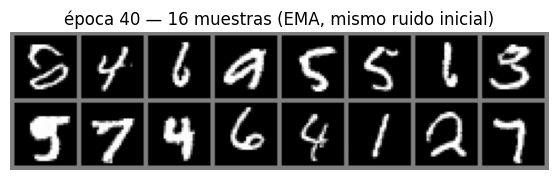

época  41/60 |   40.3s | loss   40.1167 | loss(σ grande)   3.6968 | loss(σ pequeño)  86.7863
época  42/60 |   40.5s | loss   40.0561 | loss(σ grande)   3.6818 | loss(σ pequeño)  86.8401
época  43/60 |   40.4s | loss   39.9479 | loss(σ grande)   3.6986 | loss(σ pequeño)  86.6455
época  44/60 |   40.4s | loss   40.0320 | loss(σ grande)   3.7222 | loss(σ pequeño)  86.9636
época  45/60 |   40.4s | loss   39.6903 | loss(σ grande)   3.6895 | loss(σ pequeño)  86.3281


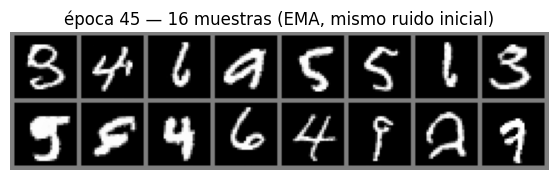

época  46/60 |   40.4s | loss   39.4146 | loss(σ grande)   3.6699 | loss(σ pequeño)  86.6202
época  47/60 |   40.3s | loss   39.7550 | loss(σ grande)   3.6534 | loss(σ pequeño)  86.7568
época  48/60 |   40.4s | loss   39.5824 | loss(σ grande)   3.6643 | loss(σ pequeño)  86.4570
época  49/60 |   40.5s | loss   39.7673 | loss(σ grande)   3.6604 | loss(σ pequeño)  86.3720
época  50/60 |   40.5s | loss   39.4838 | loss(σ grande)   3.6894 | loss(σ pequeño)  86.1214


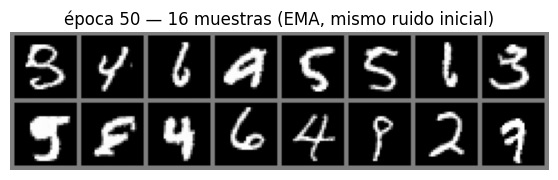

época  51/60 |   40.5s | loss   39.5029 | loss(σ grande)   3.6382 | loss(σ pequeño)  86.3147
época  52/60 |   40.3s | loss   39.1201 | loss(σ grande)   3.6500 | loss(σ pequeño)  85.7815
época  53/60 |   40.3s | loss   39.5424 | loss(σ grande)   3.6750 | loss(σ pequeño)  85.7262
época  54/60 |   40.4s | loss   39.3258 | loss(σ grande)   3.6636 | loss(σ pequeño)  85.7926
época  55/60 |   40.3s | loss   39.5156 | loss(σ grande)   3.6501 | loss(σ pequeño)  85.8412


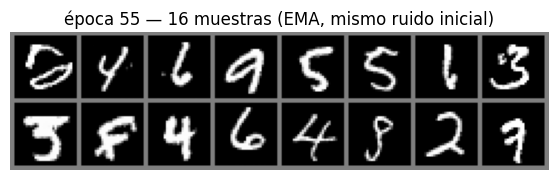

época  56/60 |   40.5s | loss   39.5424 | loss(σ grande)   3.6421 | loss(σ pequeño)  86.0468
época  57/60 |   40.5s | loss   39.2994 | loss(σ grande)   3.6637 | loss(σ pequeño)  85.6599
época  58/60 |   40.4s | loss   39.0943 | loss(σ grande)   3.6254 | loss(σ pequeño)  85.5236
época  59/60 |   40.5s | loss   39.4943 | loss(σ grande)   3.6573 | loss(σ pequeño)  85.4740
época  60/60 |   40.4s | loss   38.9309 | loss(σ grande)   3.6613 | loss(σ pequeño)  85.4858


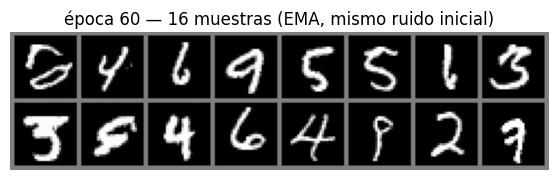

In [9]:
start_epoch = len(hist_ep["epoch"]) + 1      # permite relanzar la celda y continuar

for epoch in range(start_epoch, CFG["epochs"] + 1):
    t0 = time.time()
    ep_loss, ep_per_sigma = train_one_epoch()
    dt = time.time() - t0
    for k, v in zip(hist_ep, [epoch, ep_loss, ep_per_sigma, dt]):
        hist_ep[k].append(v)
    print(f"época {epoch:3d}/{CFG['epochs']} | {dt:6.1f}s | loss {ep_loss:9.4f} | "
          f"loss(σ grande) {np.mean(ep_per_sigma[:L // 3]):8.4f} | loss(σ pequeño) {np.mean(ep_per_sigma[-L // 3:]):8.4f}")
    save_checkpoint(epoch)

    if epoch % CFG["vis_every"] == 0 or epoch == CFG["epochs"]:
        if vis_init is None:
            g = torch.Generator(device=device).manual_seed(1234)
            vis_init = torch.rand(16, *IMG_SHAPE, generator=g, device=device) \
                       + sigmas[0] * torch.randn(16, *IMG_SHAPE, generator=g, device=device)
        samples = annealed_langevin(ema, n=16, x_init=vis_init, seed=1234)
        show_grid(samples, nrow=8, size=7, title=f"época {epoch} — 16 muestras (EMA, mismo ruido inicial)")

save_checkpoint(CFG["epochs"], name="last.pt")

## Curvas de entrenamiento

A diferencia del PCD, aquí la pérdida **sí** mide el progreso: debe bajar de forma sostenida.
Que la pérdida por nivel sea mayor en los $\sigma$ pequeños es normal (lo viste en tu `per_sigma_loss`): con poco
ruido hay que acertar detalles finos.

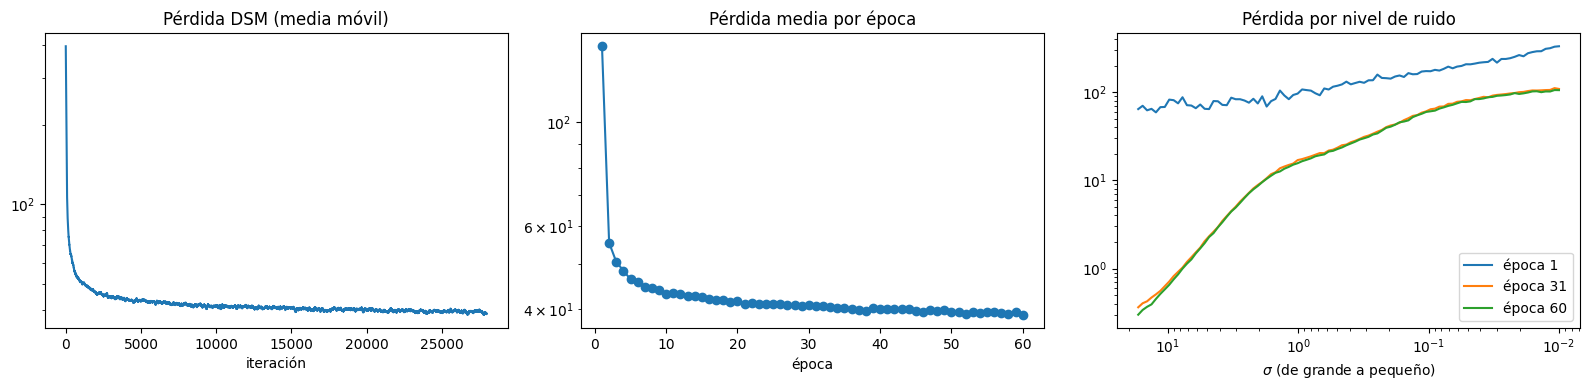

In [10]:
def smooth(v, w=100):
    v = np.asarray(v, dtype=float)
    return v if len(v) < w else np.convolve(v, np.ones(w) / w, mode="valid")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].plot(smooth(hist_it["loss"]))
ax[0].set_yscale("log"); ax[0].set_xlabel("iteración")
ax[0].set_title("Pérdida DSM (media móvil)")

ax[1].plot(hist_ep["epoch"], hist_ep["loss"], "o-")
ax[1].set_yscale("log"); ax[1].set_xlabel("época")
ax[1].set_title("Pérdida media por época")

ps = np.array(hist_ep["loss_per_sigma"])
sig = sigmas.cpu().numpy()
for e in sorted(set([0, len(ps) // 2, len(ps) - 1])):
    ax[2].loglog(sig, ps[e], label=f"época {hist_ep['epoch'][e]}")
ax[2].invert_xaxis(); ax[2].set_xlabel(r"$\sigma$ (de grande a pequeño)")
ax[2].set_title("Pérdida por nivel de ruido"); ax[2].legend()

plt.tight_layout(); plt.show()

## Evolución de la cadena por niveles

Cada fila es una muestra; cada columna, el estado al terminar un nivel de ruido (la última columna es tras el paso
final de denoising). Debajo, el diagnóstico de ruido efectivo: debería estar cerca de 1 en todos los niveles.

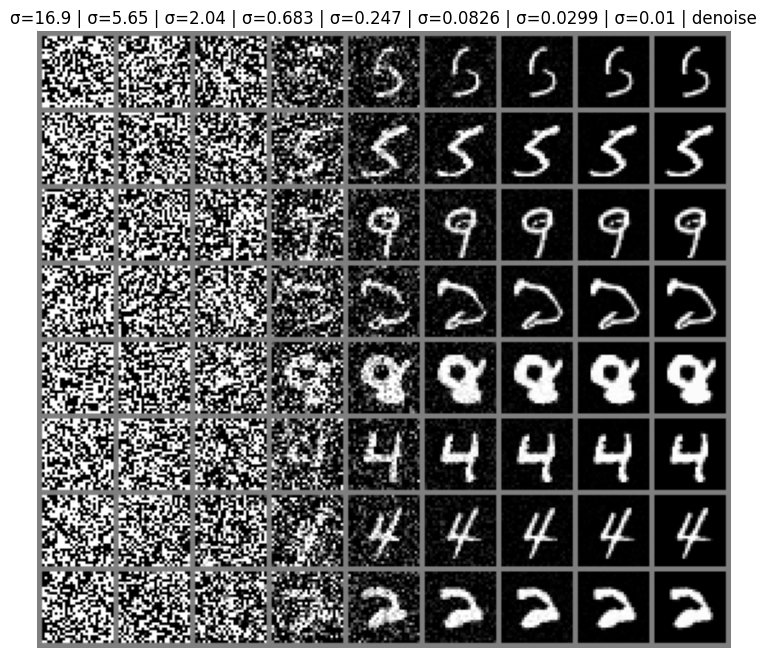

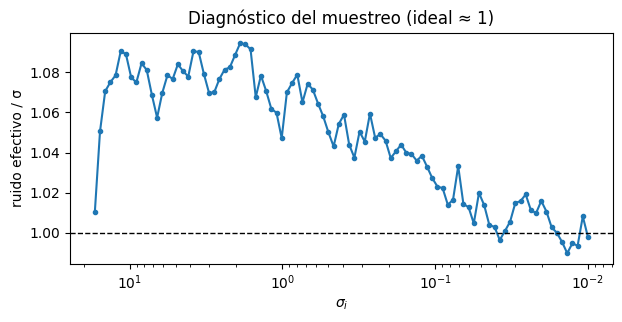

In [11]:
snap_levels = sorted(set(np.linspace(0, L - 1, 8).round().astype(int).tolist()))
x_final, snaps, eff_noise = annealed_langevin(ema, n=8, seed=123, snap_levels=snap_levels)

cols = [snaps[k] for k in snap_levels] + [x_final]
evol = torch.stack(cols, dim=1).reshape(-1, *IMG_SHAPE)
labels = [f"σ={sigmas[k].item():.3g}" for k in snap_levels] + ["denoise"]
show_grid(evol, nrow=len(cols), size=9, title=" | ".join(labels))

plt.figure(figsize=(7, 3))
plt.semilogx(sigmas.cpu().numpy(), eff_noise, ".-")
plt.axhline(1, color="k", ls="--", lw=1)
plt.gca().invert_xaxis()
plt.xlabel(r"$\sigma_i$"); plt.ylabel("ruido efectivo / σ")
plt.title("Diagnóstico del muestreo (ideal ≈ 1)"); plt.show()

64 muestras en 7.6s (481 evaluaciones de la red por muestra)


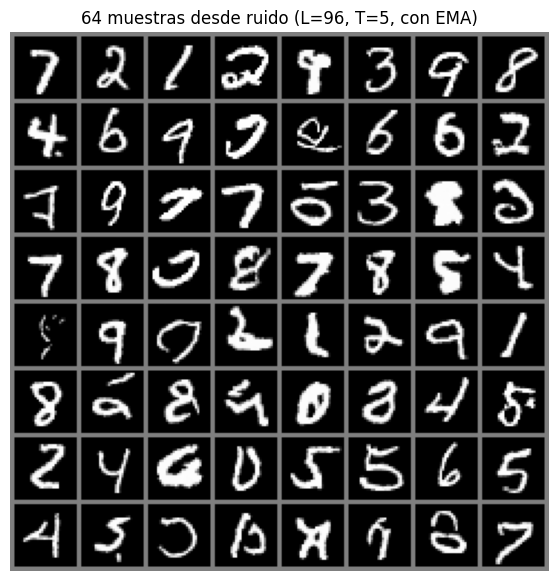

In [12]:
t0 = time.time()
x_many = annealed_langevin(ema, n=64, seed=7)
print(f"64 muestras en {time.time() - t0:.1f}s ({NFE} evaluaciones de la red por muestra)")
show_grid(x_many, nrow=8, size=7, title=f"64 muestras desde ruido (L={L}, T={CFG['T']}, con EMA)")

## Experimento: cadena larga en el último nivel

Equivalente al experimento de cadenas largas del PCD. Se toman muestras ya generadas y se siguen 2000 pasos de
Langevin en $\sigma_L$. Si el score aprendido es coherente, los dígitos deben mantenerse estables (sin degradarse ni
cambiar de forma bruscamente).

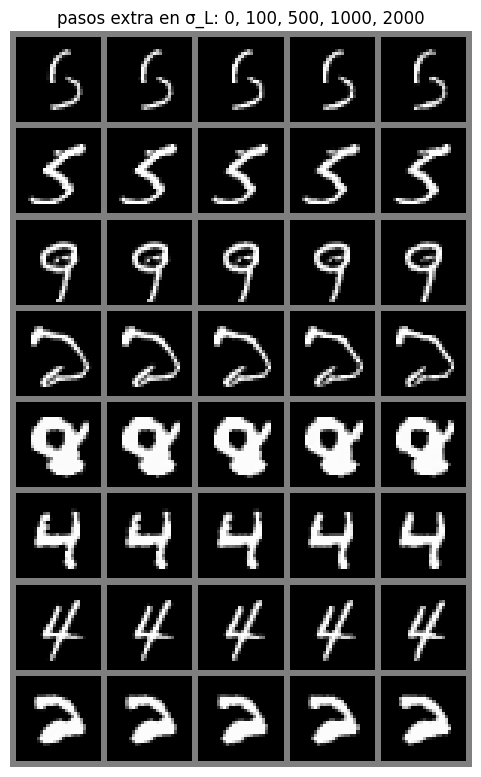

In [13]:
@torch.no_grad()
def langevin_at_sigma(net, x, sigma, steps, alpha, save_steps, seed=0):
    gen = torch.Generator(device=device).manual_seed(seed)
    x = x.to(device).clone(); s_b = sigma.expand(len(x)); snaps = {}
    if 0 in save_steps:
        snaps[0] = (x + sigma ** 2 * net(x, s_b)).clamp(0, 1).cpu()
    for k in range(1, steps + 1):
        x = x + alpha * net(x, s_b) + math.sqrt(2 * alpha) * torch.randn(x.shape, generator=gen, device=device)
        if k in save_steps:
            snaps[k] = (x + sigma ** 2 * net(x, s_b)).clamp(0, 1).cpu()   # se muestra ya limpia
    return snaps

long_steps = [0, 100, 500, 1000, 2000]
snaps_long = langevin_at_sigma(ema, x_final[:8], sigmas[-1], max(long_steps), eps, long_steps)
evol_long = torch.stack([snaps_long[s] for s in long_steps], dim=1).reshape(-1, *IMG_SHAPE)
show_grid(evol_long, nrow=len(long_steps), size=6, title="pasos extra en σ_L: " + ", ".join(map(str, long_steps)))

## Evaluación con clasificador (y comparación con PCD)

Mismo método que en el notebook de PCD: un clasificador pequeño de MNIST etiqueta 1000 muestras.

- **Distribución de clases:** en MNIST cada dígito ronda el 10 %. Cuanto más se aleje, peor diversidad.
- **Confianza:** medida sencilla de legibilidad.
- **Entropía normalizada** de la distribución de clases: 1 = los 10 dígitos igual de frecuentes.

Si existe el archivo de muestras del PCD (`CFG["pcd_samples_path"]`, en $[0,1]$), se añade a la comparación.

precisión del clasificador en test: 0.980
1000 muestras DSM en 110.5s
No se encontró el archivo de muestras del PCD; se evalúa solo DSM.
DSM (este notebook)       N= 1000 | confianza media 0.915 | entropía de clases 0.990
MNIST test (referencia)   N= 1000 | confianza media 0.970 | entropía de clases 0.997


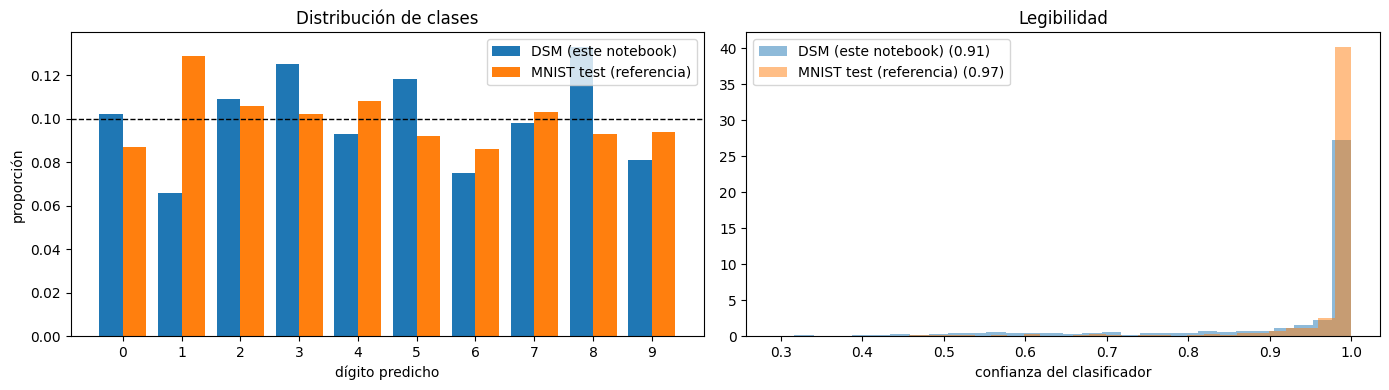

In [14]:
# --- clasificador auxiliar sobre [0, 1] ---
set_seed(0)
clf = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10),
).to(device)
opt_c = torch.optim.Adam(clf.parameters(), lr=1e-3)
clf.train()
for x, y in train_loader:
    loss = F.cross_entropy(clf(x.to(device)), y.to(device))
    opt_c.zero_grad(); loss.backward(); opt_c.step()
clf.eval()
with torch.no_grad():
    correct = sum((clf(x.to(device)).argmax(1).cpu() == y).sum().item() for x, y in test_loader)
print(f"precisión del clasificador en test: {correct / len(test_ds):.3f}")

@torch.no_grad()
def clasificar(x, bs=500):
    p = torch.cat([F.softmax(clf(x[i:i + bs].to(device)), dim=1).cpu() for i in range(0, len(x), bs)])
    return p.argmax(1).numpy(), p.max(1).values.numpy()

def entropia_norm(cls):
    f = np.bincount(cls, minlength=10) / len(cls)
    f = f[f > 0]
    return float(-(f * np.log(f)).sum() / np.log(10))

# --- muestras ---
N_EVAL = 1000
t0 = time.time()
x_eval = annealed_langevin(ema, n=N_EVAL, seed=2024)
print(f"{N_EVAL} muestras DSM en {time.time() - t0:.1f}s")

conjuntos = {"DSM (este notebook)": x_eval}
if os.path.exists(CFG["pcd_samples_path"]):
    conjuntos["PCD"] = torch.load(CFG["pcd_samples_path"]).float().clamp(0, 1)
else:
    print("No se encontró el archivo de muestras del PCD; se evalúa solo DSM.")
conjuntos["MNIST test (referencia)"] = torch.stack([test_ds[i][0] for i in range(N_EVAL)])

resultados = {}
for nombre, xs in conjuntos.items():
    cls, conf = clasificar(xs)
    resultados[nombre] = (cls, conf)
    print(f"{nombre:25s} N={len(xs):5d} | confianza media {conf.mean():.3f} | "
          f"entropía de clases {entropia_norm(cls):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
w = 0.8 / len(resultados); d = np.arange(10)
for j, (nombre, (cls, conf)) in enumerate(resultados.items()):
    ax[0].bar(d + (j - (len(resultados) - 1) / 2) * w, np.bincount(cls, minlength=10) / len(cls), w, label=nombre)
    ax[1].hist(conf, bins=30, alpha=0.5, density=True, label=f"{nombre} ({conf.mean():.2f})")
ax[0].axhline(0.1, color="k", ls="--", lw=1)
ax[0].set_xticks(d); ax[0].set_xlabel("dígito predicho"); ax[0].set_ylabel("proporción")
ax[0].set_title("Distribución de clases"); ax[0].legend()
ax[1].set_xlabel("confianza del clasificador"); ax[1].set_title("Legibilidad"); ax[1].legend()
plt.tight_layout(); plt.show()

## Guardar resultados

In [15]:
os.makedirs("resultados_dsm", exist_ok=True)
torch.save({"model": model.state_dict(), "ema": ema.state_dict(), "sigmas": sigmas.cpu(),
            "eps": eps, "cfg": CFG}, "resultados_dsm/ebm_dsm_mnist.pt")
torch.save(x_eval, "resultados_dsm/muestras_dsm_01.pt")                 # 1000 muestras en [0,1]
torchvision.utils.save_image(x_many, "resultados_dsm/muestras_dsm.png", nrow=8)
with open("resultados_dsm/historial.json", "w") as f:
    json.dump({"cfg": CFG, "L": L, "gamma": gamma, "eps": eps, "NFE": NFE,
               "hist_it": hist_it, "hist_ep": hist_ep}, f)
print(os.listdir("resultados_dsm"))

['ebm_dsm_mnist.pt', 'muestras_dsm_01.pt', 'historial.json', 'muestras_dsm.png']


## Si algo sale mal

| Síntoma | Qué probar |
|---|---|
| Muestras con ruido o grano | Mirar el diagnóstico de ruido efectivo: si queda > 1 en los últimos niveles, subir `T` (5 → 10) |
| Muestras borrosas o demasiado lisas | Diagnóstico < 1: bajar ligeramente `eps` (p. ej. ×0.7) |
| Dígitos bien formados pero poco variados | Comprobar que `sigma_1` es "auto"; subir `overlap_C` a 0.6-0.7 (más niveles) |
| Pérdida con picos | Ya hay clip y EMA; si persisten, bajar `lr` a 5e-5 |
| Muy lento al muestrear | Bajar `overlap_C` (menos niveles) o `T`, a costa de calidad |

## Referencias

- Song, Y. & Ermon, S. (2019). *Generative Modeling by Estimating Gradients of the Data Distribution.* NeurIPS.
- Song, Y. & Ermon, S. (2020). *Improved Techniques for Training Score-Based Generative Models.* NeurIPS.
- Vincent, P. (2011). *A Connection Between Score Matching and Denoising Autoencoders.* Neural Computation.
- Song, Y. et al. (2021). *Score-Based Generative Modeling through Stochastic Differential Equations.* ICLR.
- Efron, B. (2011). *Tweedie's Formula and Selection Bias.* JASA.
- Salimans, T. & Ho, J. (2021). *Should EBMs Model the Energy or the Score?* ICLR Workshop on EBMs.